# 4 — Sample several graphs from one date, train on all of them, infer on another

One date is one graph, but `train` also takes a list. Here the training set is **four random
subsets of the 2018-01-01 grid points at stride `STRIDE`**, each a `Data` with its own nodes and
its own edges; the trained model is then applied to the **complete 2019-08-01 field at native
stride 1** — 1,035,360 locations of a date it never saw, on a grid finer than anything it trained
on.

An epoch is one optimizer step per graph, so `epochs=200` over four graphs is 800 steps; the
reported `train_loss`/`val_loss` are the means over those graphs.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import torch

from nofe import NOFE
from nofe.affinity import affinity_kl_loss

# Resolve paths from the repository layout, not the process cwd: VS Code always starts kernels in
# the workspace folder (`jupyter.notebookFileRoot` is ignored since 2024.4), while `_execute.py`
# runs from this directory. Walk up from the cwd looking for the repo root, so both agree.
REPO = next(
    (
        ancestor
        for ancestor in (Path.cwd(), *Path.cwd().parents)
        if (ancestor / "pyproject.toml").is_file()
    ),
    None,
)
if REPO is None:
    raise RuntimeError(f"run this notebook from inside the nofe checkout, not {Path.cwd()}")
ERA5 = REPO / "examples" / "era5"
DATA = ERA5 / "data"

# The example data is not in Git (21 MB per date), so fail with the fetch command rather than the
# opaque `StopIteration`/`FileNotFoundError` the loader would otherwise raise.
if not (DATA / "2018-01-01.nc").exists():
    raise FileNotFoundError(
        f"missing {DATA / '2018-01-01.nc'}\n"
        "The ERA5 inputs are not committed. Fetch them once with:\n"
        f"  mkdir -p {DATA}\n"
        f"  cp /Volumes/T7-storage/ERA5/data/2018-01-0{{1,2}}.nc {DATA}/"
    )

# The notebooks import the ERA5 helpers straight from the example scripts, so the loader, the
# graph generator and the globe plot have exactly one implementation in the repo. They are
# imported after `sys.path` is extended, which is why the noqa markers below are needed: the ERA5
# demo lives in `scripts/`, its graph generator here in `utilities/`, and the shared graph helpers
# one level up in `examples/`.
sys.path.insert(0, str(ERA5 / "scripts"))
sys.path.insert(0, str(ERA5 / "utilities"))
sys.path.insert(0, str(REPO / "examples"))
import era5  # noqa: E402
from era5_graph import Era5Graph  # noqa: E402
from graph_utils import knn_indices  # noqa: E402


def kl(on, embedding) -> float:
    """Mean KL between a graph's own feature affinities and an embedding of its rows."""
    return float(affinity_kl_loss(on.x, embedding, on.edge_index, on.num_nodes))


def pca_baseline(data, dims: int = 3) -> torch.Tensor:
    """Best linear projection to ``dims`` dimensions: the reference the model has to beat."""
    centred = data.x - data.x.mean(dim=0, keepdim=True)
    _, _, basis = torch.linalg.svd(centred, full_matrices=False)
    return centred @ basis[:dims].T


def knn_agreement(reference: torch.Tensor, candidate: torch.Tensor, k: int = 10) -> float:
    """Mean share of exact k-nearest neighbours two point sets have in common."""
    ref = reference.detach().cpu().numpy()
    cand = candidate.detach().cpu().numpy()
    ref_nn = knn_indices(ref, k)
    cand_nn = knn_indices(cand, k)
    shared = [len(set(a) & set(b)) / k for a, b in zip(ref_nn, cand_nn, strict=True)]
    return float(np.mean(shared))


def close(a: torch.Tensor, b: torch.Tensor, rtol: float = 1e-4) -> bool:
    """Relative agreement in units of the embedding's own scale."""
    return bool((a - b).abs().max() <= rtol * a.abs().max())


print("nofe ready")


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/laueb4818/github/NOFE-pkg/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


nofe ready


## Sample subgraphs from the first date

Each subgraph keeps a random `FRACTION` of the grid points, drawn with its own seed: same radius,
fewer points, so about 3% of the kept nodes end up with no neighbour inside their own subgraph.
They are not broken — a node with no incoming edge is embedded from its own features through the
root weight — but they carry no neighbourhood information, which is why the in-degree is printed
rather than assumed.

In [2]:
from graph_utils import merge_queries, radius_edges

STRIDE = 8
# Chord on the unit sphere: a 2.5 degree arc, the same neighbourhood as notebooks 1-3.
RADIUS = 0.04363
FRACTION = 0.5
NUM_GRAPHS = 4

graph = Era5Graph(radius=RADIUS, stride=STRIDE, data_dir=DATA)
features, latitudes, longitudes = graph.load("2018-01-01")
positions = graph.positions(latitudes, longitudes)
flat = features.reshape(-1, features.shape[2])
print(f"{flat.shape[0]} grid points on 2018-01-01, {flat.shape[1]} variables each")


def sample_graph(seed: int):
    """A random subset of the grid points, with a radius neighbourhood of its own."""
    keep = np.random.default_rng(seed).random(flat.shape[0]) < FRACTION
    return merge_queries(
        positions[keep],
        flat[keep],
        edge_builder=lambda pos, sources, targets: radius_edges(
            pos, RADIUS, sources=sources, targets=targets
        ),
    )


graphs = [sample_graph(seed) for seed in range(NUM_GRAPHS)]
for index, sampled in enumerate(graphs):
    degrees = torch.bincount(sampled.edge_index[1], minlength=sampled.num_nodes)
    print(
        f"graph {index}: {sampled.num_nodes} nodes, {sampled.num_edges} edges, "
        f"mean in-degree {degrees.float().mean():.2f}, isolated {int((degrees == 0).sum())}"
    )


16020 grid points on 2018-01-01, 11 variables each
graph 0: 7986 nodes, 54730 edges, mean in-degree 6.85, isolated 243
graph 1: 8030 nodes, 57112 edges, mean in-degree 7.11, isolated 245
graph 2: 8038 nodes, 57344 edges, mean in-degree 7.13, isolated 230
graph 3: 8113 nodes, 57850 edges, mean in-degree 7.13, isolated 250


## Train on the list

`train` runs one optimizer step per graph per epoch and averages the losses it reports. `loss` on a
list is the unweighted mean over graphs, so it equals the mean of the per-graph scores below —
`loss([a, b, c, d]) == mean(loss(a), loss(b), loss(c), loss(d))`.

In [3]:
CONFIG = {
    "width": 8,
    "ker_width": 32,
    "epochs": 200,
    "seed": 0,
    "early_stopping": True,
    "verbose": True,
    "log_every": 25,
    "nystrom": 0.25,
}

model = NOFE(dim=3, config=CONFIG)
history = model.train(graphs)
per_graph = [model.loss(sampled) for sampled in graphs]
print(f"{len(history)} epochs, {len(history) * len(graphs)} optimizer steps")
print(f"loss {history[0]['train_loss']:.5f} -> {history[-1]['train_loss']:.6f}")
print("mean KL per graph:", [round(value, 6) for value in per_graph])
print(f"mean KL over the list: {model.loss(graphs):.6f}")
assert abs(model.loss(graphs) - np.mean(per_graph)) < 1e-6


epoch   25/200  train 0.007489  val 0.007721


epoch   50/200  train 0.007267  val 0.007318


epoch   75/200  train 0.006838  val 0.007245


epoch  100/200  train 0.006872  val 0.007088


epoch  112/200  train 0.006670  val 0.007123
112 epochs, 448 optimizer steps
loss 0.04798 -> 0.006670
mean KL per graph: [0.006819, 0.006897, 0.006311, 0.007037]
mean KL over the list: 0.006766


## Infer on the full second date, at native resolution

Training ran on 50% samples at `STRIDE`, because the objective needs every training edge resident
on every epoch. Inference does not: it is one forward pass per chunk, so it can cover the whole
grid. The model is therefore applied to **all 719 x 1440 = 1,035,360 grid points** of 2019-08-01 at
stride 1, a grid it has never seen.

The radius has to shrink with the stride — 2.5 degrees at stride 1 would be ~917M edges (~40 GB) —
and `0.005454` keeps the neighbourhood the fine grid can hold. `embed` stays single-graph and
returns one row per node.

In [4]:
INFER_STRIDE = 1
INFER_RADIUS = 0.005454
full_graph = Era5Graph(radius=INFER_RADIUS, stride=INFER_STRIDE, data_dir=DATA)
full_features, full_latitudes, full_longitudes = full_graph.load("2019-08-01")
full = full_graph.build(full_features, full_latitudes, full_longitudes)
print(f"full grid: {full.num_nodes} nodes, {full.num_edges} edges")

embedding = model.embed(full)
print("embedding on 2019-08-01:", tuple(embedding.shape))
print(f"mean KL on the unseen date: {model.loss(full):.6f}")
assert embedding.shape == (full.num_nodes, 3)
assert torch.isfinite(embedding).all()


radius 0.00545 (chord on the unit sphere, 0.31 deg arc), 1035360 nodes, 22049808 edges
mean neighbours per receiver: 21.30  max: 865
nodes without a neighbour:    0 (0.00%)
full grid: 1035360 nodes, 22049808 edges


embedding on 2019-08-01: (1035360, 3)


mean KL on the unseen date: 0.002147


## Plot the embedding of the unseen date

R/G/B are the three embedding dimensions, one `pcolormesh` quad per grid point, scaled by the
5th/95th percentile spread (`era5.PERCENTILE`).

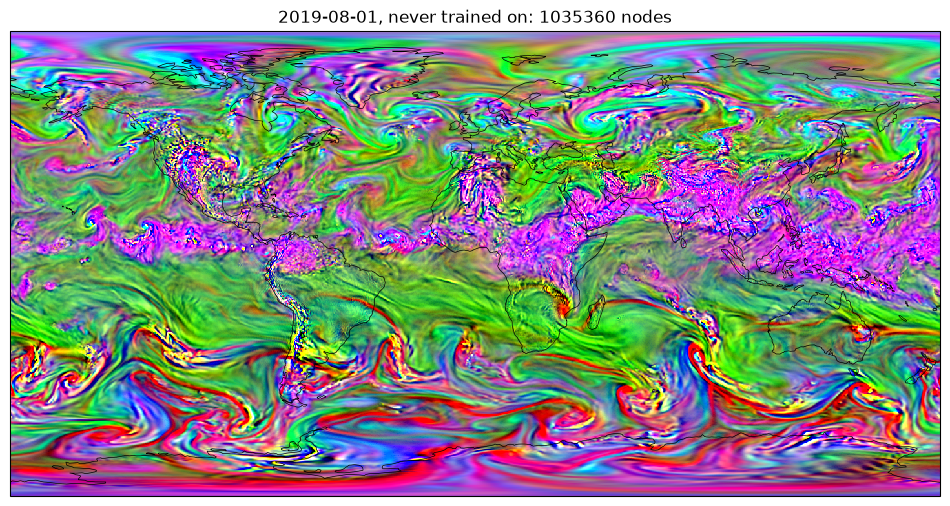

In [5]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

figure, axis = plt.subplots(
    1, 1, figsize=(12.0, 6.5), subplot_kw={"projection": ccrs.PlateCarree()}
)
axis.set_global()
era5.draw_globe(axis, full_latitudes, full_longitudes, embedding.numpy())
axis.coastlines(linewidth=0.5)
axis.set_title(f"2019-08-01, never trained on: {full.num_nodes} nodes")
plt.show()


## Takeaways

|Fact|Why it matters|
|---|---|
|`train` takes a list|One operator covers many graphs; an epoch is one step per graph|
|Graphs need only matching widths|The samples are independent `Data` objects with their own edges|
|`loss` on a list is a mean over graphs|Each graph counts once, whatever its node count|
|Inference needs no training grid|A coarse, sub-sampled model embeds the full-resolution field|
|`embed` takes one graph|Inference loop over the list if many embeddings are needed|